# Bivariate & Multivariate Analysis

---
## What is Bivariate Analysis?
> **Bivariate Analysis** involves the simultaneous analysis of **two variables (attributes)** to determine the empirical relationship between them.

Unlike Univariate Analysis (which examines the distribution and summary of a single column), Bivariate Analysis answers questions like:
- *Does variable X affect or correlate with variable Y?*
- *How does the distribution of a numeric feature vary across different categories?*
- *Is there an association between two categorical features?*

### The 3 Core Combinations:
1. **Numerical - Numerical**: Scatterplot, Lineplot
2. **Numerical - Categorical**: Bar Plot, Box Plot, KDE / Distribution Plot
3. **Categorical - Categorical**: Contingency Table (Cross-tab) Heatmap & Clustermap
4. **Multivariate Analysis**: Pairplot, Pivot Table Clustermap

---
## 0. Setup & Loading Datasets
We use standard benchmark datasets for machine learning exploratory data analysis:
- `titanic` (`train.csv` in local folder) — Passenger demographics & survival
- `tips` — Total bill, tip, gender, smoker, day, time, party size
- `flights` — Monthly passenger traffic over time (1949–1960)
- `iris` — Flower petal & sepal measurements across 3 species

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure Seaborn style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Load datasets
tips = sns.load_dataset("tips")
titanic = pd.read_csv("train.csv")
flights = sns.load_dataset("flights")
iris = sns.load_dataset("iris")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [2]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
titanic.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [4]:
flights.head(3)

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132


In [5]:
iris.head(3)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa


---
## 1. Scatterplot (Numerical — Numerical)
A **Scatterplot** maps points along Cartesian coordinates to display values for two continuous variables.

### Use Cases:
- Discover **correlation** (positive, negative, non-linear, or none).
- Spot **clusters** and **outliers**.
- Add extra dimensions using:
  - `hue`: categorical color coding (e.g., `sex`)
  - `style`: marker shapes (e.g., `smoker`)
  - `size`: marker scaling (e.g., party `size`)

#### Example 1: Tips Dataset (`total_bill` vs `tip`)

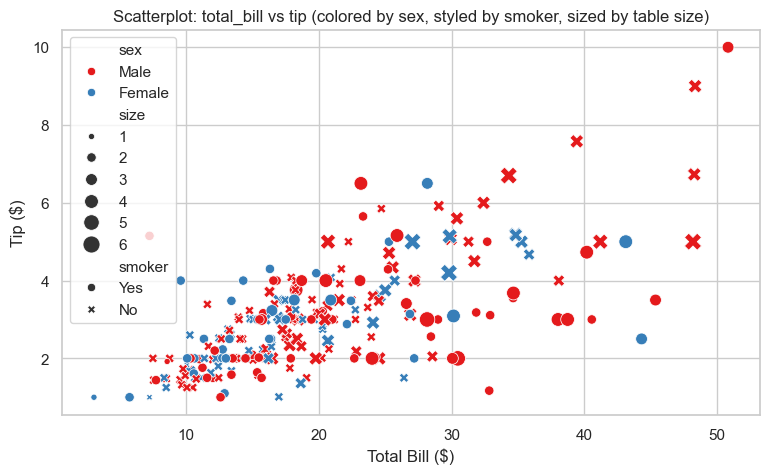

In [6]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="sex",
    style="smoker",
    size="size",
    sizes=(20, 150),
    palette="Set1"
)
plt.title("Scatterplot: total_bill vs tip (colored by sex, styled by smoker, sized by table size)")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.show()

#### Example 2: Titanic Dataset (`Age` vs `Fare` by `Survived`)

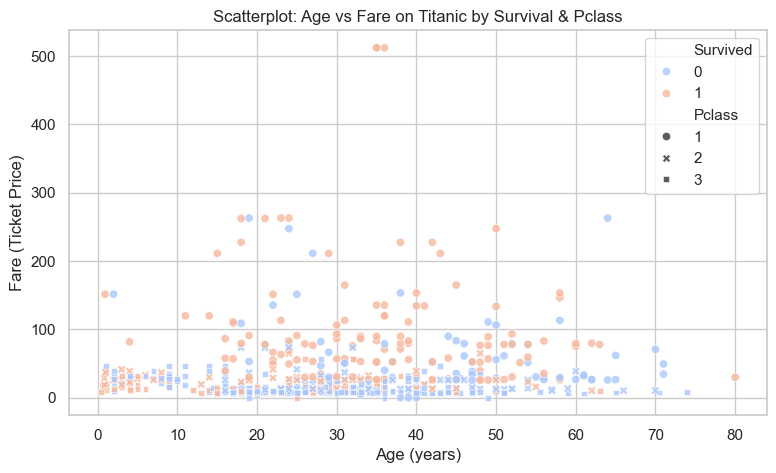

In [7]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=titanic,
    x="Age",
    y="Fare",
    hue="Survived",
    style="Pclass",
    palette="coolwarm",
    alpha=0.8
)
plt.title("Scatterplot: Age vs Fare on Titanic by Survival & Pclass")
plt.xlabel("Age (years)")
plt.ylabel("Fare (Ticket Price)")
plt.show()

---
## 2. Bar Plot (Numerical — Categorical)
A **Bar Plot** represents an aggregate estimate (mean by default) for a numeric variable across different categories, with black vertical error bars indicating confidence intervals.

### Use Cases:
- Compare average quantities across groups (e.g. average Age by Passenger Class).
- Stratify by a second categorical dimension with `hue`.

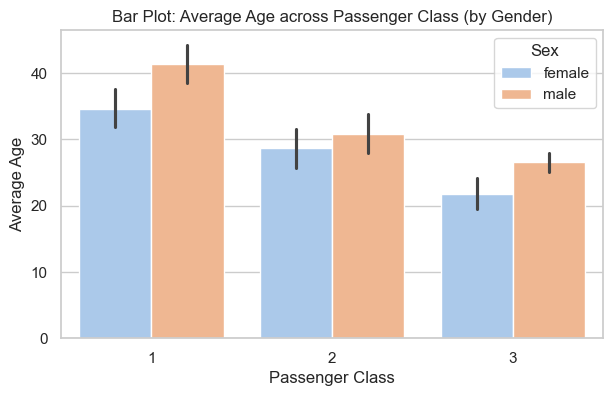

In [8]:
plt.figure(figsize=(7, 4))
sns.barplot(data=titanic, x="Pclass", y="Age", hue="Sex", palette="pastel")
plt.title("Bar Plot: Average Age across Passenger Class (by Gender)")
plt.xlabel("Passenger Class")
plt.ylabel("Average Age")
plt.show()

#### Survival Probability Bar Plot (Mean of binary target `Survived`):
Because `Survived` is coded as `0` and `1`, its mean equals the **survival rate**.

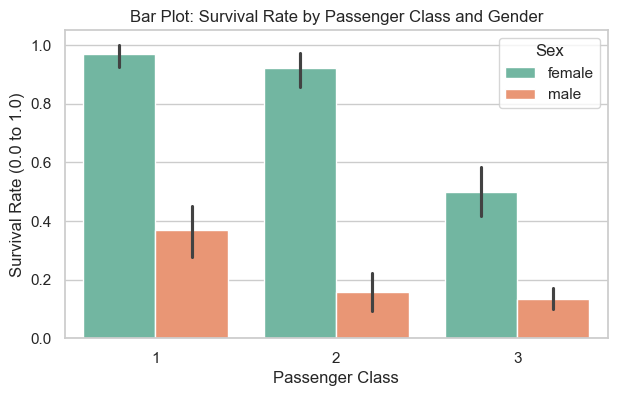

In [9]:
plt.figure(figsize=(7, 4))
sns.barplot(data=titanic, x="Pclass", y="Survived", hue="Sex", palette="Set2")
plt.title("Bar Plot: Survival Rate by Passenger Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (0.0 to 1.0)")
plt.show()

---
## 3. Box Plot (Numerical — Categorical)
A **Box Plot** depicts the full distribution (median, quartiles, and outliers) of a numeric variable partitioned by categorical categories.

### Key Metrics:
- **Central Line**: Median (Q2)
- **Box Boundaries**: Q1 (25th percentile) and Q3 (75th percentile) -> Interquartile Range (IQR)
- **Whiskers**: Values within 1.5 * IQR
- **Points**: Outliers

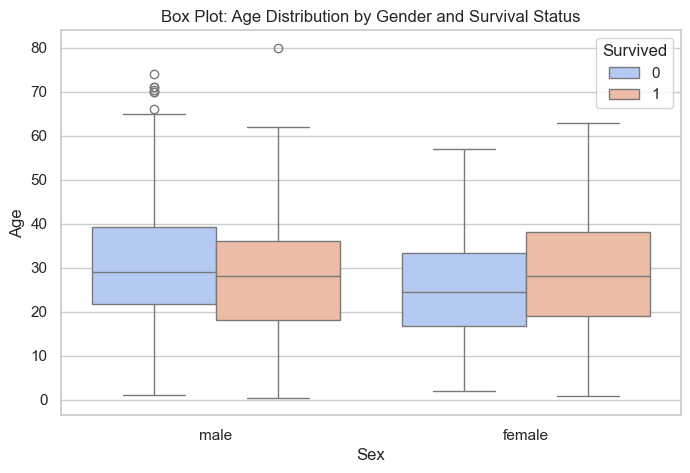

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=titanic, x="Sex", y="Age", hue="Survived", palette="coolwarm")
plt.title("Box Plot: Age Distribution by Gender and Survival Status")
plt.xlabel("Sex")
plt.ylabel("Age")
plt.show()

---
## 4. Distplot / KDE Plot (Numerical — Categorical)
Used to compare probability density curves of a numerical variable across different categorical classes.

> **Seaborn Evolution Note**:
> - Legacy syntax used: `sns.distplot(titanic[titanic['Survived']==0]['Age'], hist=False)`
> - In modern Seaborn (v0.11+), `distplot` is deprecated. Use **`sns.kdeplot()`** directly with `hue='Survived'` for cleaner, modern code.

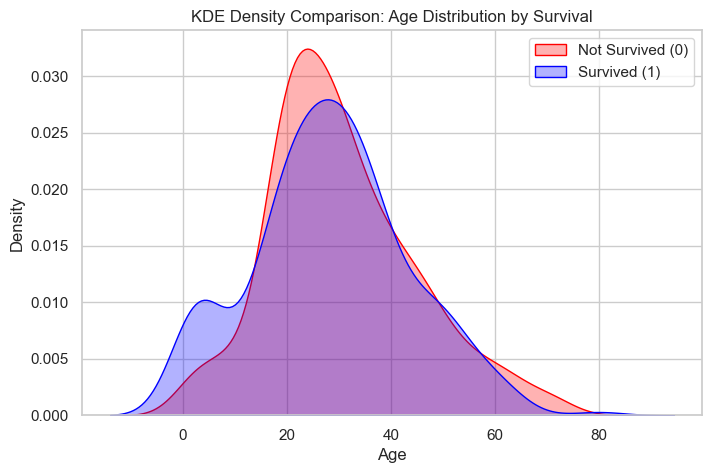

In [11]:
plt.figure(figsize=(8, 5))
# Modern Seaborn kdeplot comparing distributions:
sns.kdeplot(titanic[titanic["Survived"] == 0]["Age"], label="Not Survived (0)", color="red", fill=True, alpha=0.3)
sns.kdeplot(titanic[titanic["Survived"] == 1]["Age"], label="Survived (1)", color="blue", fill=True, alpha=0.3)

plt.title("KDE Density Comparison: Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Density")
plt.legend()
plt.show()

#### Modern idiomatic one-liner using `hue`:

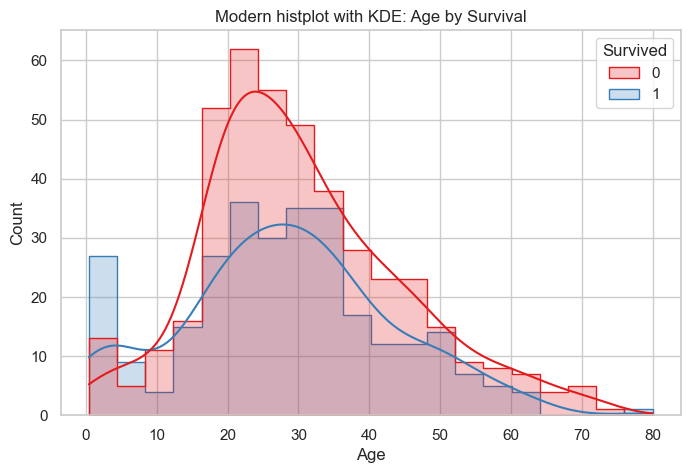

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=titanic, x="Age", hue="Survived", kde=True, element="step", palette="Set1")
plt.title("Modern histplot with KDE: Age by Survival")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

---
## 5. HeatMap (Categorical — Categorical)
To analyze the relationship between **two categorical variables**, we create a contingency table using `pd.crosstab()` and visualize the counts or percentages as a **HeatMap**.

### Use Cases:
- Frequency co-occurrence across categories (e.g., `Pclass` vs `Survived`).
- Conditional proportions and percentage likelihoods.

Contingency Table (Counts):
 Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


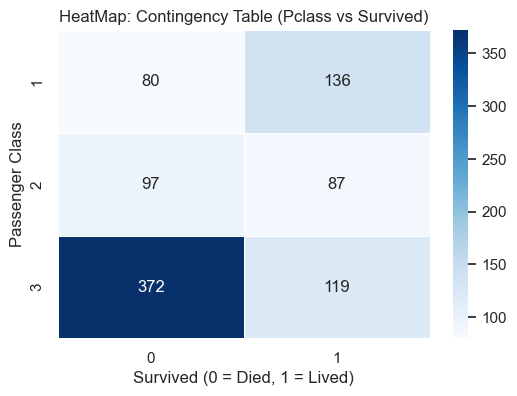

In [13]:
# Step 1: Create a contingency table (crosstab)
ct = pd.crosstab(titanic["Pclass"], titanic["Survived"])
print("Contingency Table (Counts):\n", ct)

# Step 2: Plot Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", linewidths=0.5)
plt.title("HeatMap: Contingency Table (Pclass vs Survived)")
plt.xlabel("Survived (0 = Died, 1 = Lived)")
plt.ylabel("Passenger Class")
plt.show()

#### Survival percentage across Embarkation Ports (`groupby().mean()`):

Survival Percentage by Embarked Port (%):
 Embarked
C    55.36
Q    38.96
S    33.70
Name: Survived, dtype: float64


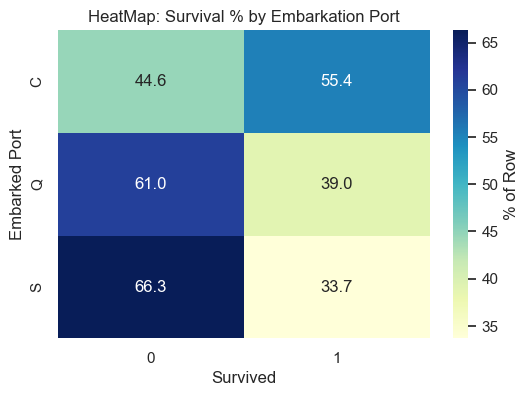

In [14]:
# Survival rate percentage by Embarked port
survival_by_embarked = titanic.groupby("Embarked")["Survived"].mean() * 100
print("Survival Percentage by Embarked Port (%):\n", survival_by_embarked.round(2))

# Normalized percentage heatmap
ct_percent = pd.crosstab(titanic["Embarked"], titanic["Survived"], normalize="index") * 100
plt.figure(figsize=(6, 4))
sns.heatmap(ct_percent, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "% of Row"})
plt.title("HeatMap: Survival % by Embarkation Port")
plt.xlabel("Survived")
plt.ylabel("Embarked Port")
plt.show()

---
## 6. ClusterMap (Categorical — Categorical)
A **ClusterMap** performs **Hierarchical Agglomerative Clustering** on the rows and columns of a matrix, reordering them so that categories with similar patterns are grouped together.

### Example: `Parch` (Parents/Children) vs `Survived`

Parch vs Survived Crosstab:
 Survived    0    1
Parch             
0         445  233
1          53   65
2          40   40
3           2    3
4           4    0
5           4    1
6           1    0


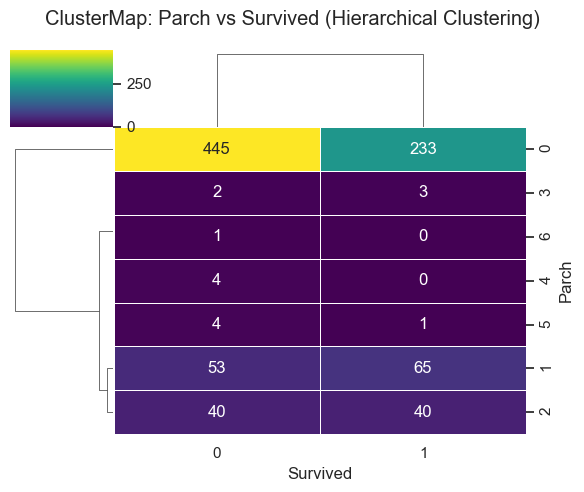

In [15]:
parch_crosstab = pd.crosstab(titanic["Parch"], titanic["Survived"])
print("Parch vs Survived Crosstab:\n", parch_crosstab)

cm = sns.clustermap(parch_crosstab, annot=True, fmt="d", cmap="viridis", figsize=(6, 5), linewidths=0.5)
cm.fig.subplots_adjust(top=0.9)
cm.fig.suptitle("ClusterMap: Parch vs Survived (Hierarchical Clustering)")
plt.show()

---
## 7. Pairplot (Multivariate Numerical Analysis)
A **Pairplot** produces a grid of pairwise bivariate scatter plots for all numerical features in a dataset, with univariate distribution plots (histograms/KDE) along the diagonal.

### Example 1: Iris Dataset

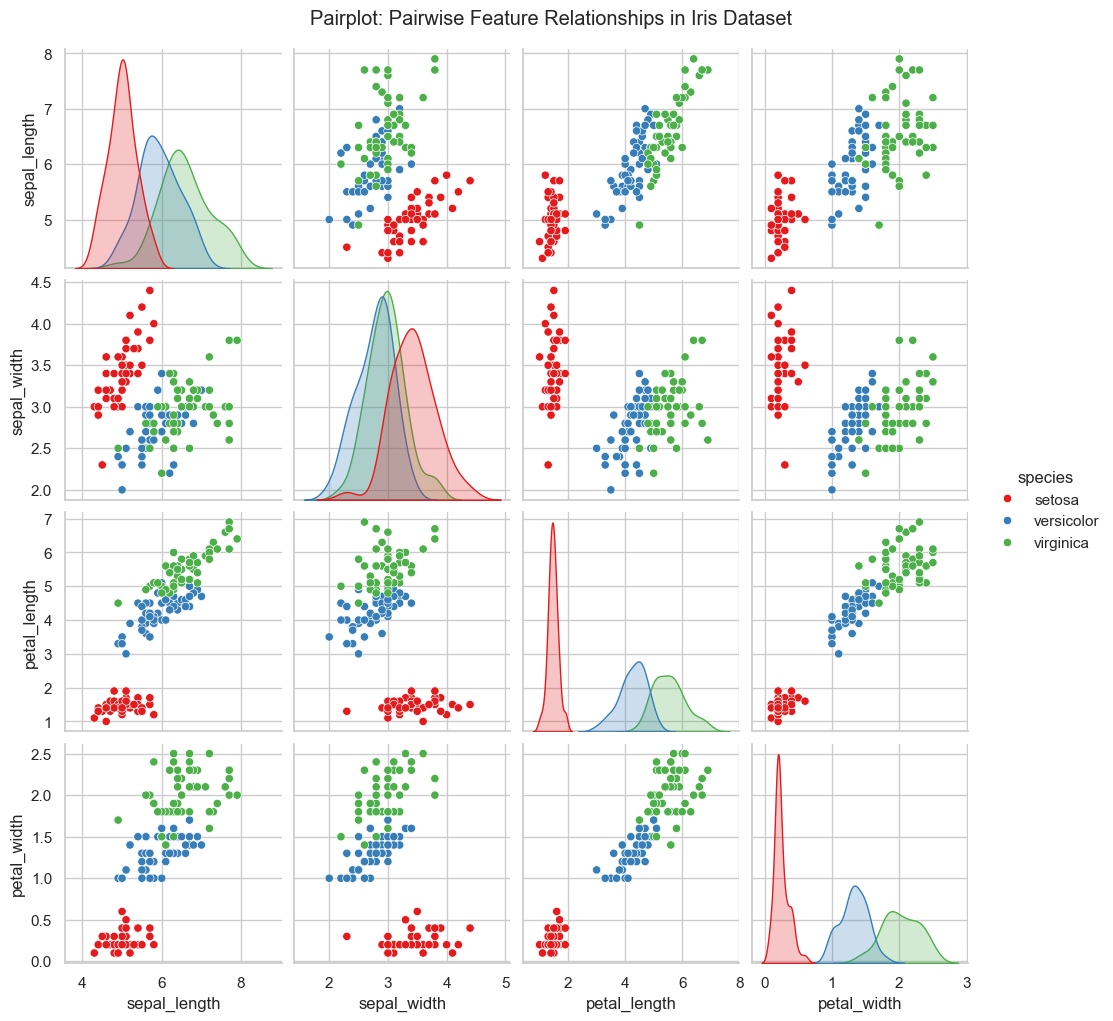

In [16]:
sns.pairplot(iris, hue="species", palette="Set1", corner=False)
plt.suptitle("Pairplot: Pairwise Feature Relationships in Iris Dataset", y=1.02)
plt.show()

#### Example 2: Titanic Dataset Pairplot

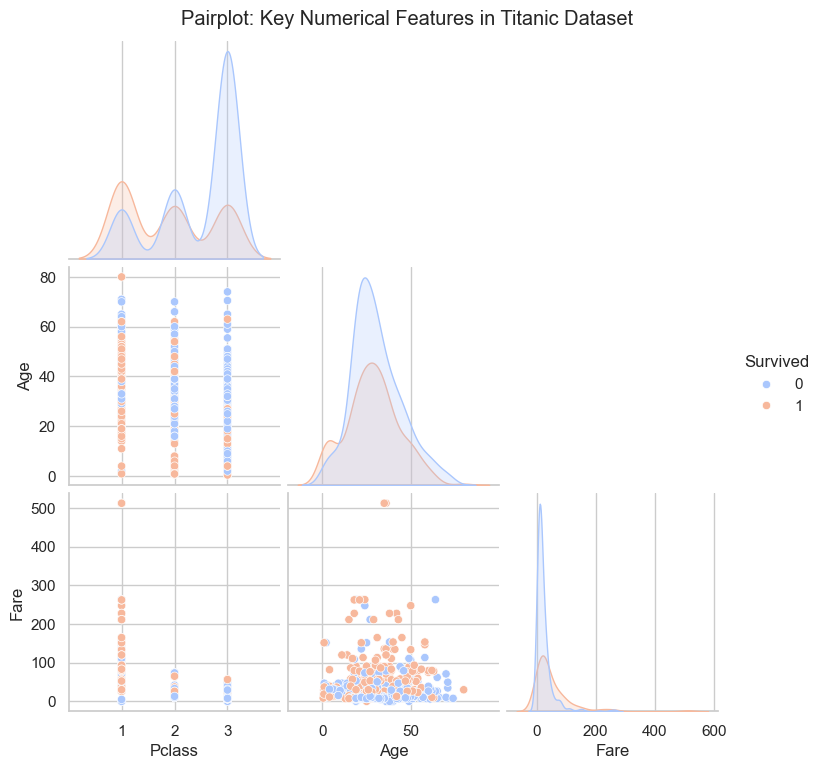

In [17]:
selected_cols = ["Survived", "Pclass", "Age", "Fare"]
sns.pairplot(titanic[selected_cols].dropna(), hue="Survived", palette="coolwarm", corner=True)
plt.suptitle("Pairplot: Key Numerical Features in Titanic Dataset", y=1.02)
plt.show()

---
## 8. Lineplot (Numerical — Numerical with Time/Order)
A **Lineplot** connects observations sequentially, typically used when one numeric variable represents time or an ordered sequence (like years or timestamps).

### Example: Flights Dataset (Annual Passenger Growth)

   year  passengers
0  1949        1520
1  1950        1676
2  1951        2042
3  1952        2364
4  1953        2700


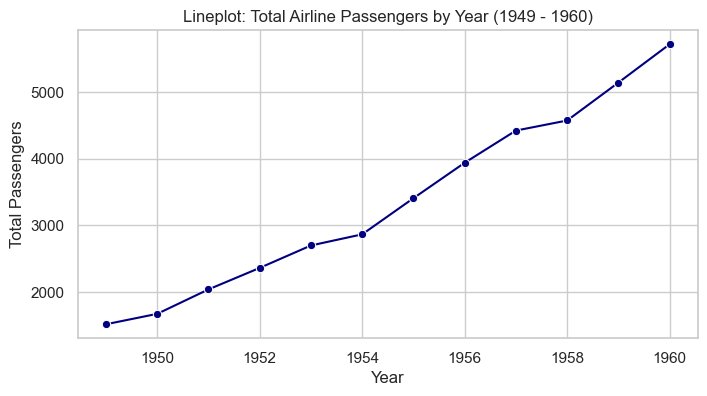

In [18]:
# Aggregate total passengers per year
annual_passengers = flights.groupby("year", as_index=False)["passengers"].sum()
print(annual_passengers.head())

plt.figure(figsize=(8, 4))
sns.lineplot(data=annual_passengers, x="year", y="passengers", marker="o", color="navy")
plt.title("Lineplot: Total Airline Passengers by Year (1949 - 1960)")
plt.xlabel("Year")
plt.ylabel("Total Passengers")
plt.show()

---
## 9.Pivot Table Heatmap & Clustermap
Transforming row-based records into a 2D matrix using `pivot_table()`, then visualizing patterns across months and years.

In [19]:
# Create 2D pivot table: months on rows, years on columns
flights_pivot = flights.pivot_table(values="passengers", index="month", columns="year")
flights_pivot

/var/folders/dx/zd4nxtxd4fsb__p09t61ld9w0000gn/T/ipykernel_58280/4142774292.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  flights_pivot = flights.pivot_table(values="passengers", index="month", columns="year")


year,1949,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,1960
month,,,,,,,,,,,,
Jan,112.0,115.0,145.0,171.0,196.0,204.0,242.0,284.0,315.0,340.0,360.0,417.0
Feb,118.0,126.0,150.0,180.0,196.0,188.0,233.0,277.0,301.0,318.0,342.0,391.0
Mar,132.0,141.0,178.0,193.0,236.0,235.0,267.0,317.0,356.0,362.0,406.0,419.0
Apr,129.0,135.0,163.0,181.0,235.0,227.0,269.0,313.0,348.0,348.0,396.0,461.0
May,121.0,125.0,172.0,183.0,229.0,234.0,270.0,318.0,355.0,363.0,420.0,472.0
Jun,135.0,149.0,178.0,218.0,243.0,264.0,315.0,374.0,422.0,435.0,472.0,535.0
Jul,148.0,170.0,199.0,230.0,264.0,302.0,364.0,413.0,465.0,491.0,548.0,622.0
Aug,148.0,170.0,199.0,242.0,272.0,293.0,347.0,405.0,467.0,505.0,559.0,606.0
Sep,136.0,158.0,184.0,209.0,237.0,259.0,312.0,355.0,404.0,404.0,463.0,508.0


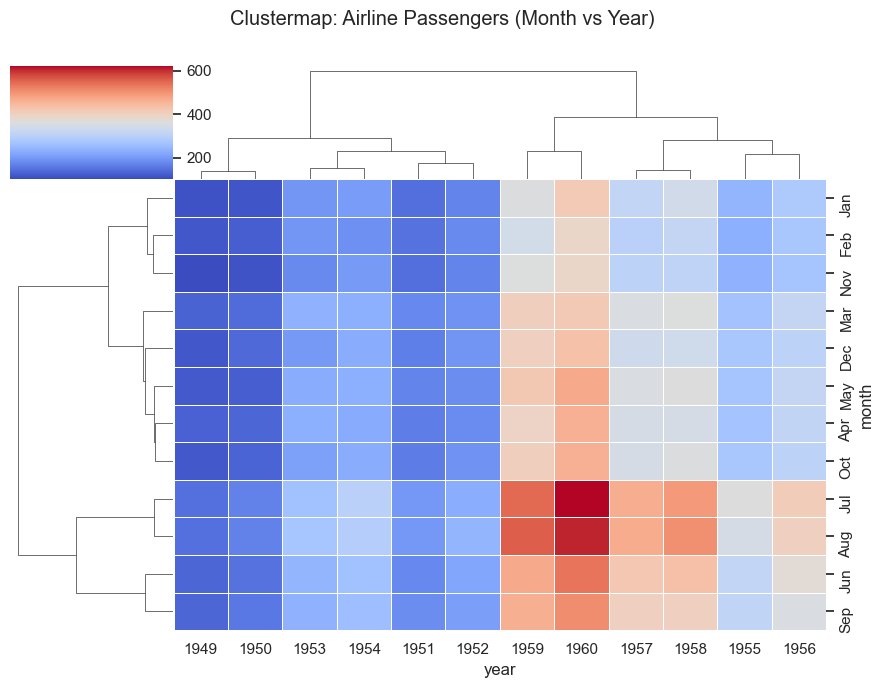

In [20]:
# Clustermap groups similar months (summer peaks) and years together
cm_flights = sns.clustermap(flights_pivot, cmap="coolwarm", linewidths=0.5, figsize=(9, 7))
cm_flights.fig.subplots_adjust(top=0.9)
cm_flights.fig.suptitle("Clustermap: Airline Passengers (Month vs Year)")
plt.show()

---
## Summary Cheat Sheet: Bivariate Analysis

| Variable Types | Recommended Visualizations | Key Seaborn Functions |
| :--- | :--- | :--- |
| **Numerical vs. Numerical** | Scatterplot, Lineplot | `sns.scatterplot()`, `sns.lineplot()` |
| **Numerical vs. Categorical** | Barplot, Boxplot, KDE / Distplot, Violinplot | `sns.barplot()`, `sns.boxplot()`, `sns.kdeplot()` |
| **Categorical vs. Categorical** | Contingency Heatmap, Clustermap | `sns.heatmap(pd.crosstab())`, `sns.clustermap()` |
| **Multivariate (All Numeric)** | Pairplot, Correlation Heatmap | `sns.pairplot()`, `sns.heatmap(df.corr())` |
| **Time-Series / Matrix** | Pivot Table Clustermap | `sns.clustermap(df.pivot_table())` |